# Forecasting net interest income

A bank's interest income changes as loans amortize, borrowers prepay, floating
coupons reset, and new business replaces runoff. Funding also matures and
reprices. This study starts with a EUR 1 million loan book funded by term
deposits and forecasts monthly **accrued, undiscounted NII** over two years.

We compare runoff, full replacement, and replacement plus planned growth under
base, +100 bp and -100 bp curves. All market inputs are illustrative and defined
below; nothing downloads live data.

The adjacent [nii_forecast.py](nii_forecast.py) contains the reusable classes.
QS supplies contractual amortization, rate observations, prepayment-adjusted
loan receipts and native deposit coupon amounts. The Python layer handles
dated new production, recursive rollover and monthly accrual allocation.
See the [loan study](../valuation/loans/loans.ipynb) for the instrument details and
the [portfolio introduction](../sensitivity/portfolio.ipynb) for native aggregation.

In [1]:
from datetime import date
from pathlib import Path
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
import quantsupport as qs

from nii_forecast import (
    ForecastPosition, ForecastPortfolio, ProductionTemplate,
    RolloverRule, NewProduction, IncomeForecaster,
)

AS_OF = "2026-03-01"
HORIZON = "2028-03-01"
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

## A market for existing coupons and future originations

The ESTR curve is the discount/funding reference; EURIBOR3m projects floating
loan resets and supplies the refinancing benchmark. Each curve uses continuously
compounded zero rates on Actual/360. The known initial EURIBOR fixing on 27 February is 2.70%:
market shocks change subsequent resets, while this observed coupon stays fixed.

For this deterministic exercise, forward curves are scenario assumptions about
future rates. No stochastic paths or option time value enter the calculation.

In [2]:
PILLARS = ["0D", "1Y", "2Y", "5Y", "10Y"]
ZERO_RATES = {
    "ESTR": [0.0225, 0.0230, 0.0240, 0.0260, 0.0280],
    "EURIBOR3m": [0.0270, 0.0280, 0.0300, 0.0320, 0.0340],
}


def make_context():
    quotes = qs.QuoteStore.from_dict({
        "reference_date": AS_OF,
        "quotes": [
            {"identifier": f"ZeroRate_EUR_{index}_{tenor}", "mid": rate}
            for index, rates in ZERO_RATES.items()
            for tenor, rate in zip(PILLARS, rates)
        ],
    })
    curves = [qs.CurveConfiguration(
        market_index=index,
        quotes=[f"ZeroRate_EUR_{index}_{tenor}" for tenor in PILLARS],
        day_counter="Actual360", interpolator="Linear",
    ) for index in ZERO_RATES]
    fixings = qs.FixingStore()
    fixings.add(qs.MarketIndex.EURIBOR3m, "2026-02-27", 0.027)
    context = qs.PricingContext(
        quotes=quotes, curves=curves, fixings=fixings,
        csa_policy=qs.SingleCurveCSADiscountPolicy("EUR", "ESTR"),
        fixed_income_policy=qs.FixedIncomeDiscountPolicy({"EUR": "ESTR"}),
    )
    context.pricer_configurations = [qs.PricerConfiguration.loan(
        refinancing_benchmark_index=qs.MarketIndex.EURIBOR3m,
    )]
    return context


pd.DataFrame(ZERO_RATES, index=PILLARS).rename_axis("zero-rate pillar")

,ESTR,EURIBOR3m
zero-rate pillar,,
0D,0.02,0.03
1Y,0.02,0.03
2Y,0.02,0.03
5Y,0.03,0.03
10Y,0.03,0.03


## Supply the portfolio and retain its product groups

The fixed mortgage pool has French amortization and rate-sensitive CPR. The
floating pool amortizes over two years and resets quarterly despite paying
monthly. Its CPR is a constant 6%. Deposit funding is a six-month liability.

`ForecastPortfolio` retains the original `qs.Trade` objects and their segment
labels, and exposes an equivalent native `qs.Portfolio` through `.native`.
Keep this metadata when building an existing portfolio: native portfolio
aggregation compresses compatible rows and does not expose its membership
list back to Python. Position notional overrides and signs are respected.

For a seasoned book, supply contracts that reflect actual current balances and
remaining repayment terms. Future CPR does not reconstruct past prepayments.

In [3]:
refinancing = qs.PrepaymentModelConfiguration.refinancing_incentive(
    base_cpr=0.04, incentive_multiplier=5.0, maximum_cpr=0.40,
)
floating_cpr = qs.PrepaymentModelConfiguration.constant_annual_cpr(0.06)

fixed_loan = qs.Loan(
    identifier="FIXED-MORTGAGES", start_date=AS_OF, maturity_date="2029-03-01",
    notional=600_000, currency="EUR", repayment="French", payment_frequency="Monthly",
    coupons=[qs.FixedRateCoupon(rate=qs.InterestRate(
        rate=0.0475, day_counter="Actual365", compounding="Simple",
    ))], prepayment=refinancing,
)
floating_loan = qs.Loan(
    identifier="FLOATING-LOANS", start_date=AS_OF, maturity_date=HORIZON,
    notional=400_000, currency="EUR", repayment="French", payment_frequency="Monthly",
    coupons=[qs.FloatingRateCoupon(index="EURIBOR3m", spread=0.015, day_counter="Actual360")],
    fixing_frequency="Quarterly", index_tenor="3M", fixing_lag=2,
    amortization_rate=0.042, prepayment=floating_cpr,
)
funding = qs.FixedRateDeposit(
    identifier="TERM-FUNDING", start_date=AS_OF, maturity_date="2026-09-01",
    notional=1_000_000, rate=0.018, currency="EUR", discount_index="ESTR",
    day_counter="Actual365", compounding="Simple",
)
portfolio = ForecastPortfolio("EUR-BANK", [
    ForecastPosition("Fixed mortgage pool", "Fixed loans", qs.Trade(fixed_loan, AS_OF)),
    ForecastPosition("Floating loan pool", "Floating loans", qs.Trade(floating_loan, AS_OF)),
    ForecastPosition("Customer term funding", "Term funding", qs.Trade(funding, AS_OF, "PayShort")),
])

print(portfolio.native)
display(pd.DataFrame([
    {"position": p.name, "segment": p.segment, "side": str(p.trade.side),
     "notional_eur": p.trade.instrument.notional}
    for p in portfolio.positions
]))

Portfolio(identifier="EUR-BANK", trades=3)


,position,segment,side,notional_eur
0,Fixed mortgage pool,Fixed loans,LongReceive,"600,000.00"
1,Floating loan pool,Floating loans,LongReceive,"400,000.00"
2,Customer term funding,Term funding,PayShort,"1,000,000.00"


## Define replacement terms and planned new business

Prepayment is principal, not income. QS reduces subsequent expected coupons
when borrowers prepay. `RolloverRule` separately replaces scheduled principal
(including maturity) and prepaid principal. Both fractions are one below:
immediate replacement preserves each segment's balance. Set either fraction
below one for attrition, or use `lag_days` for delayed origination.

Every replacement is a new QS instrument starting on its origination date.
It also amortizes, prepays and creates replacement orders. Same-day orders
are pooled by segment, template and origin to keep the number of cohorts small.

Fixed new-business pricing is the scenario curve's simple start-to-maturity
forward, converted to the coupon day count, plus a commercial margin. It locks
at origination. This transparent policy is **not a par amortizing-loan solve**.
Floating replacements use EURIBOR3m plus a contractual spread. The native
refinancing CPR model compares the old coupon with its index benchmark, without
replacement-loan margins, fees or transaction costs.

The growth plan adds EUR 50,000 of floating loans and matching term funding
every quarter, starting three months into the forecast. Planned cohorts are
also eligible for their segment's rollover rule.

In [4]:
fixed_production = ProductionTemplate(
    "24m fixed mortgages", tenor_months=24, index="EURIBOR3m", margin=0.014,
    prepayment=refinancing,
)
floating_production = ProductionTemplate(
    "24m floating loans", tenor_months=24, rate_type="floating",
    index="EURIBOR3m", margin=0.015, day_counter="Actual360",
    prepayment=floating_cpr,
)
funding_production = ProductionTemplate(
    "3m term funding", kind="deposit", tenor_months=3, side="PayShort",
    index="ESTR", margin=-0.004, day_counter="Actual365",
)
rollovers = [
    RolloverRule("Fixed loans", fixed_production),
    RolloverRule("Floating loans", floating_production),
    RolloverRule("Term funding", funding_production),
]
growth = []
for month in range(3, 24, 3):
    start = str(qs.Date.parse(AS_OF).advance(month, "Months"))
    growth.extend([
        NewProduction(start, 50_000, "Floating loans", floating_production),
        NewProduction(start, 50_000, "Term funding", funding_production),
    ])

pd.DataFrame([
    {"date": p.date, "segment": p.segment, "amount_eur": p.amount, "template": p.template.name}
    for p in growth
])

,date,segment,amount_eur,template
0,2026-06-01,Floating loans,50000,24m floating loans
1,2026-06-01,Term funding,50000,3m term funding
2,2026-09-01,Floating loans,50000,24m floating loans
3,2026-09-01,Term funding,50000,3m term funding
4,2026-12-01,Floating loans,50000,24m floating loans
5,2026-12-01,Term funding,50000,3m term funding
6,2027-03-01,Floating loans,50000,24m floating loans
7,2027-03-01,Term funding,50000,3m term funding
8,2027-06-01,Floating loans,50000,24m floating loans
9,2027-06-01,Term funding,50000,3m term funding


## Run complete forecasts under each scenario

Each call projects existing cohorts once from the forecast date, then processes
dated principal and production events. It does not advance the context month
by month and reset the original loans' prepayment state.

Scenario scopes rebuild affected curves. Their rate changes flow through
floating resets, refinancing CPR and new-business prices. Historical fixings
and the original contracts remain unchanged. Existing fixed coupons do not
reprice. No PV sensitivity is treated as an NII sensitivity.

In [5]:
forecaster = IncomeForecaster(AS_OF, HORIZON, currency="EUR")
modes = {
    "Runoff": dict(),
    "Replacement": dict(rollovers=rollovers),
    "Growth": dict(rollovers=rollovers, planned=growth),
}
results = {}
with make_context() as context:
    native_existing = context.evaluate(portfolio.native, [qs.Request.Cashflows])
    for scenario_name, bump in [("Base", 0.0), ("Up 100 bp", 0.01), ("Down 100 bp", -0.01)]:
        shocks = [] if bump == 0 else [
            qs.Shock(index, bump, qs.ScenarioType.Absolute) for index in ZERO_RATES
        ]
        with qs.Scenario(shocks=shocks):
            for mode, settings in modes.items():
                results[(scenario_name, mode)] = forecaster.forecast(context, portfolio, **settings)

summary = pd.DataFrame([
    {"scenario": scenario, "mode": mode,
     "two_year_nii_eur": result.monthly.nii.sum(),
     "delta_nii_eur": result.monthly.nii.sum() - results[("Base", mode)].monthly.nii.sum(),
     "closing_assets_eur": result.monthly.asset_balance.iloc[-1],
     "closing_liabilities_eur": result.monthly.liability_balance.iloc[-1],
     "new_cohorts": len(result.productions)}
    for (scenario, mode), result in results.items()
])
summary

,scenario,mode,two_year_nii_eur,delta_nii_eur,closing_assets_eur,closing_liabilities_eur,new_cohorts
0,Base,Runoff,"44,433.36",0.00,"160,051.95",0.00,0
1,Base,Replacement,"53,175.38",0.00,"1,000,000.00","1,000,000.00",55
2,Base,Growth,"62,283.35",0.00,"1,350,000.00","1,350,000.00",69
3,Up 100 bp,Runoff,"49,185.54","4,752.19","179,064.93",0.00,0
4,Up 100 bp,Replacement,"49,719.43","-3,455.95","1,000,000.00","1,000,000.00",55
5,Up 100 bp,Growth,"58,833.50","-3,449.84","1,350,000.00","1,350,000.00",69
6,Down 100 bp,Runoff,"39,706.83","-4,726.52","142,149.80",0.00,0
7,Down 100 bp,Replacement,"55,998.89","2,823.51","1,000,000.00","1,000,000.00",55
8,Down 100 bp,Growth,"65,100.77","2,817.42","1,350,000.00","1,350,000.00",69


## Read the income and balance evolution

Monthly income is allocated by coupon accrual dates, not payment dates.
A coupon paid after the forecast horizon still contributes its earned portion
inside the horizon. For simple interest, differences of cumulative contractual
year fractions allocate the native coupon amount across reporting months.
Signs are applied once: asset interest is income, and liability interest is
expense. Principal movements stay in the balance and cash ledgers.

Balance events occur on `(period_start, period_end]`; production on the forecast
date is included in the first period. An origination on the horizon date
changes closing balances and earns no in-horizon interest. Accrual periods use
`[period_start, period_end)`.

**Residual cash/funding is explicit and earns zero in this teaching model.**
Runoff can repay deposits faster than assets: a negative cumulative principal
cash balance shows the resulting funding requirement. That runoff NII excludes
the cost of financing this requirement. Balanced replacement and growth avoid
that gap here. Add treasury cash and funding instruments before using the
forecast for a fully funded business plan.

,period_start,period_end,interest_income,asset_balance,interest_expense,liability_balance,nii,cumulative_nii,net_principal_cashflow,cumulative_principal_cash
0,2026-03-01,2026-04-01,"3,867.21","1,000,000.00","1,528.77","1,000,000.00","2,338.45","2,338.45",0.00,0.00
1,2026-04-01,2026-05-01,"3,739.59","1,000,000.00","1,479.45","1,000,000.00","2,260.14","4,598.59",0.00,0.00
2,2026-05-01,2026-06-01,"3,861.98","1,050,000.00","1,528.77","1,050,000.00","2,333.22","6,931.80",0.00,0.00
3,2026-06-01,2026-07-01,"3,939.19","1,050,000.00","1,558.62","1,050,000.00","2,380.57","9,312.37",-0.00,-0.00
4,2026-07-01,2026-08-01,"4,069.11","1,050,000.00","1,610.57","1,050,000.00","2,458.54","11,770.91",0.00,0.00
5,2026-08-01,2026-09-01,"4,068.53","1,100,000.00","1,610.57","1,100,000.00","2,457.96","14,228.87",0.00,0.00
6,2026-09-01,2026-10-01,"4,132.31","1,100,000.00","1,764.70","1,100,000.00","2,367.61","16,596.48",-0.00,-0.00
7,2026-10-01,2026-11-01,"4,270.90","1,100,000.00","1,823.53","1,100,000.00","2,447.37","19,043.85",0.00,-0.00
8,2026-11-01,2026-12-01,"4,134.77","1,150,000.00","1,764.70","1,150,000.00","2,370.07","21,413.92",0.00,0.00
9,2026-12-01,2027-01-01,"4,477.74","1,150,000.00","1,931.04","1,150,000.00","2,546.70","23,960.62",-0.00,-0.00


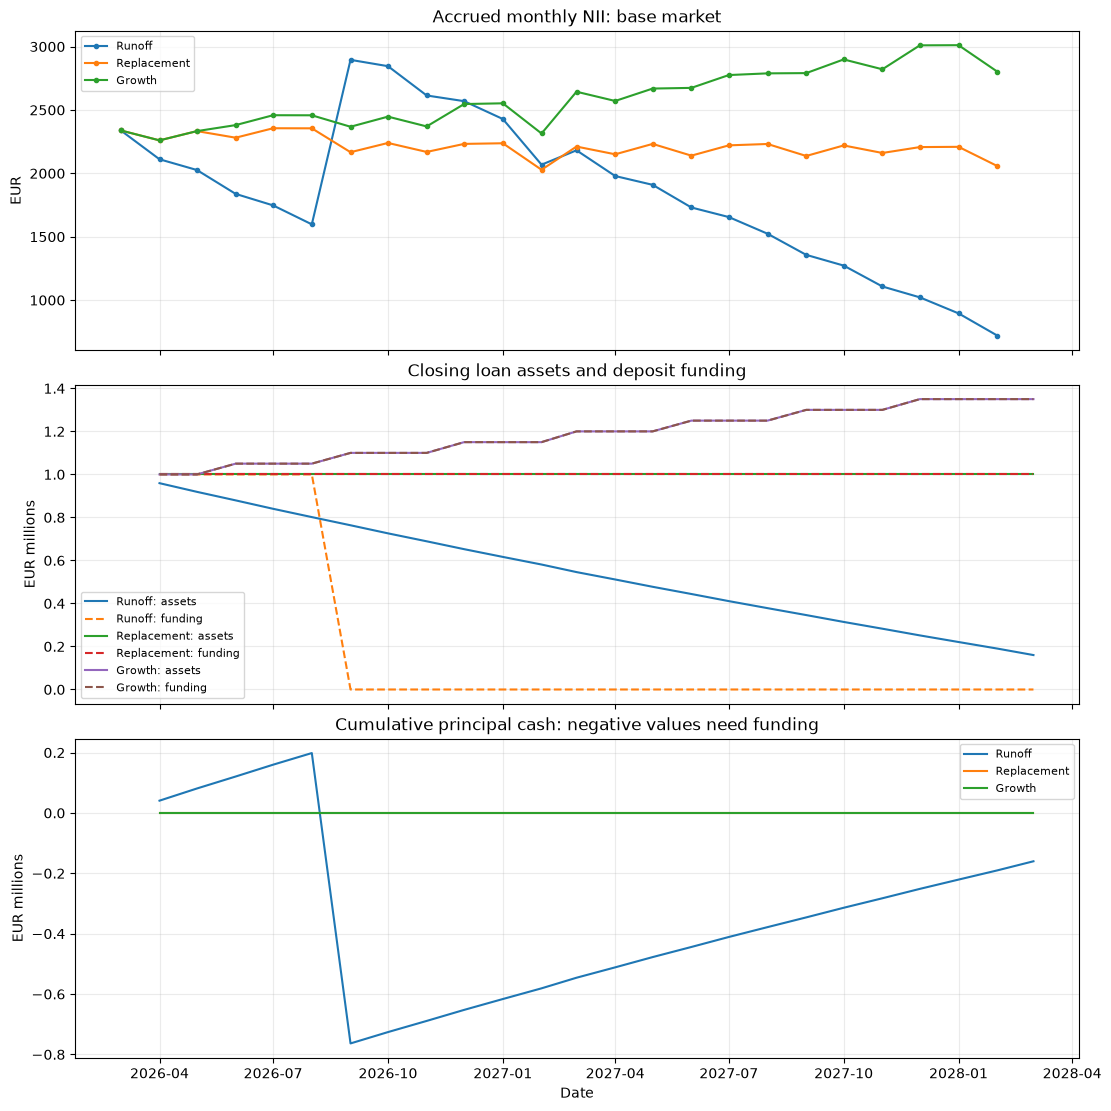

In [6]:
base = results[("Base", "Growth")]
display(base.monthly)

fig, axes = plt.subplots(3, 1, figsize=(11, 11), sharex=True, constrained_layout=True)
for mode in modes:
    monthly = results[("Base", mode)].monthly
    axes[0].plot(pd.to_datetime(monthly.period_start), monthly.nii, marker=".", label=mode)
    axes[1].plot(pd.to_datetime(monthly.period_end), monthly.asset_balance / 1e6, label=f"{mode}: assets")
    axes[1].plot(pd.to_datetime(monthly.period_end), monthly.liability_balance / 1e6, linestyle="--", label=f"{mode}: funding")
    axes[2].plot(pd.to_datetime(monthly.period_end), monthly.cumulative_principal_cash / 1e6, label=mode)
axes[0].set(title="Accrued monthly NII: base market", ylabel="EUR")
axes[1].set(title="Closing loan assets and deposit funding", ylabel="EUR millions")
axes[2].set(title="Cumulative principal cash: negative values need funding", ylabel="EUR millions", xlabel="Date")
for axis in axes:
    axis.legend(loc="best", fontsize=8)
    axis.grid(alpha=0.25)
plt.show()

## Attribute income and inspect new production

`income_detail` retains the cohort, original position, segment, and whether
the income comes from existing, replacement, or planned business. The production
audit shows actual origination dates, amounts, initial all-in coupons and
maturities. `initial_rate` is the initial quote; floating coupons reset later.
`cashflows` retains full-life coupon and principal receipts for each projected
cohort, including payments beyond the forecast horizon. Initial advances are
tracked separately through production in the balance ledger.

The rate-down scenario raises fixed-loan prepayments in this example and changes
the volume and coupon of replacements. The resulting NII effect combines this
behaviour with floating resets and deposit renewal costs.

origin,existing,planned,replacement
segment,,,
Fixed loans,"35,419.37",0.00,"21,470.82"
Floating loans,"18,087.96","11,425.79","23,573.33"
Term funding,"-9,073.97","-1,804.03","-36,815.91"


,date,segment,origin,cohort,template,amount,initial_rate,maturity_date
0,2026-04-01,Fixed loans,replacement,replacement-0004,24m fixed mortgages,"22,841.07",0.05,2028-04-01
1,2026-04-01,Floating loans,replacement,replacement-0005,24m floating loans,"17,946.58",0.04,2028-04-01
2,2026-05-01,Fixed loans,replacement,replacement-0006,24m fixed mortgages,"23,617.57",0.05,2028-05-01
3,2026-05-01,Floating loans,replacement,replacement-0007,24m floating loans,"18,680.96",0.04,2028-05-01
4,2026-06-01,Fixed loans,replacement,replacement-0008,24m fixed mortgages,"24,268.23",0.05,2028-06-01
5,2026-06-01,Floating loans,replacement,replacement-0009,24m floating loans,"19,350.64",0.04,2028-06-01
6,2026-06-01,Floating loans,planned,planned-0010,24m floating loans,"50,000.00",0.04,2028-06-01
7,2026-06-01,Term funding,planned,planned-0011,3m term funding,"50,000.00",0.02,2026-09-01
8,2026-07-01,Fixed loans,replacement,replacement-0012,24m fixed mortgages,"25,095.27",0.05,2028-07-01
9,2026-07-01,Floating loans,replacement,replacement-0013,24m floating loans,"22,385.81",0.04,2028-07-01


,period_start,period_end,segment,book_side,opening_balance,scheduled_principal,prepayment,production,closing_balance
0,2026-03-01,2026-04-01,Fixed loans,asset,"600,000.00","15,497.93","7,343.14","22,841.07","600,000.00"
1,2026-04-01,2026-05-01,Fixed loans,asset,"600,000.00","16,352.14","7,265.43","23,617.57","600,000.00"
2,2026-05-01,2026-06-01,Fixed loans,asset,"600,000.00","17,076.88","7,191.35","24,268.23","600,000.00"
3,2026-06-01,2026-07-01,Fixed loans,asset,"600,000.00","17,977.88","7,117.39","25,095.27","600,000.00"
4,2026-07-01,2026-08-01,Fixed loans,asset,"600,000.00","18,751.56","7,049.10","25,800.67","600,000.00"
5,2026-08-01,2026-09-01,Fixed loans,asset,"600,000.00","19,625.41","6,980.78","26,606.19","600,000.00"
6,2026-09-01,2026-10-01,Fixed loans,asset,"600,000.00","20,603.45","6,914.94","27,518.39","600,000.00"
7,2026-10-01,2026-11-01,Fixed loans,asset,"600,000.00","21,457.47","6,852.52","28,310.00","600,000.00"
8,2026-11-01,2026-12-01,Fixed loans,asset,"600,000.00","22,491.99","6,790.17","29,282.16","600,000.00"


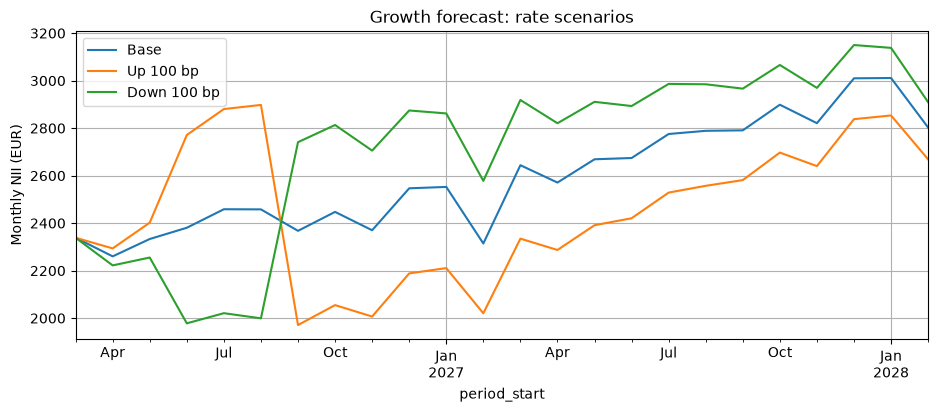

,scenario,first_year_fixed_prepayment_eur
0,Base,"68,022.03"
1,Up 100 bp,"42,735.21"
2,Down 100 bp,"93,345.05"


In [7]:
attribution = base.income_detail.pivot_table(
    index="segment", columns="origin", values="interest", aggfunc="sum", fill_value=0,
)
display(attribution)
display(base.productions.head(12))
display(base.balances.head(9))

scenario_income = pd.DataFrame({
    scenario: results[(scenario, "Growth")].monthly.nii.to_numpy()
    for scenario in ["Base", "Up 100 bp", "Down 100 bp"]
}, index=pd.to_datetime(base.monthly.period_start))
scenario_income.plot(figsize=(11, 4), title="Growth forecast: rate scenarios", ylabel="Monthly NII (EUR)", grid=True)
plt.show()

pd.DataFrame([
    {"scenario": scenario, "first_year_fixed_prepayment_eur":
     result.balances.query("segment == 'Fixed loans'").iloc[:12].prepayment.sum()}
    for (scenario, mode), result in results.items() if mode == "Runoff"
])

## Reconcile the forecast

These checks use a hand-calculated first-month NII, native portfolio receipts,
and the principal balance identity. Native loan leg 0 contains scheduled receipts,
leg 1 prepayments, and leg 2 recoveries; recovery/default accounting is excluded
from this example. Existing contractual terms and known resets stay fixed in
all scenarios. See [test_nii_forecast.py](test_nii_forecast.py) for additional
partial-period, delayed renewal, position-size, and scenario-isolation checks.

In [8]:
runoff = results[("Base", "Runoff")]
replacement = results[("Base", "Replacement")]

# First month: all opening principal earns interest; repayments occur at month end.
expected_march = (
    600_000 * 0.0475 * 31 / 365
    + 400_000 * (0.027 + 0.015) * 31 / 360
    - 1_000_000 * 0.018 * 31 / 365
)
assert math.isclose(runoff.monthly.nii.iloc[0], expected_march, abs_tol=1e-7)

# Original coupons align with monthly boundaries; take those earned inside the horizon.
native_coupons = native_existing.coupons
earned = native_coupons[
    native_coupons.type.isin(["FixedRateCoupon", "FloatingRateCoupon"])
    & (native_coupons.accrual_start >= AS_OF)
    & (native_coupons.accrual_end <= HORIZON)
]
np.testing.assert_allclose(runoff.monthly.nii.sum(), earned.amount.sum(), atol=1e-7, rtol=0)

np.testing.assert_allclose(replacement.monthly.asset_balance, 1_000_000, atol=1e-6, rtol=0)
np.testing.assert_allclose(replacement.monthly.liability_balance, 1_000_000, atol=1e-6, rtol=0)
np.testing.assert_allclose(base.monthly.asset_balance, base.monthly.liability_balance, atol=1e-6, rtol=0)
np.testing.assert_allclose(base.monthly.net_principal_cashflow, 0, atol=1e-6, rtol=0)
assert math.isclose(base.monthly.asset_balance.iloc[-1], 1_350_000, abs_tol=1e-6)

for result in results.values():
    balances = result.balances
    np.testing.assert_allclose(
        balances.closing_balance,
        balances.opening_balance + balances.production - balances.scheduled_principal - balances.prepayment,
        atol=1e-6, rtol=0,
    )
    assert math.isclose(result.income_detail.interest.sum(), result.monthly.nii.sum(), abs_tol=1e-7)
    assert math.isclose(balances.production.sum(), result.productions.amount.sum(), abs_tol=1e-6)

first_month = [results[(scenario, "Growth")].monthly.nii.iloc[0]
               for scenario in ["Base", "Up 100 bp", "Down 100 bp"]]
np.testing.assert_allclose(first_month, expected_march, atol=1e-7, rtol=0)

print("Passed: hand-calculated NII, native portfolio interest, recursive replacement, growth/funding and balance identities.")

Passed: hand-calculated NII, native portfolio interest, recursive replacement, growth/funding and balance identities.
